In [3]:
# step 0:
import sys

print(sys.executable)

C:\Users\ARYAN\anaconda3\envs\emotion_cnn\python.exe


In [4]:
# Step 1:
import pandas as pd

data = pd.read_csv("train.csv")

print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())

Dataset shape: (28709, 2)
Columns: ['emotion', 'pixels']


In [5]:
# step 2:
print("Emotion labels:")
print(data["emotion"].value_counts().sort_index())


Emotion labels:
emotion
0    3995
1     436
2    4097
3    7215
4    4830
5    3171
6    4965
Name: count, dtype: int64


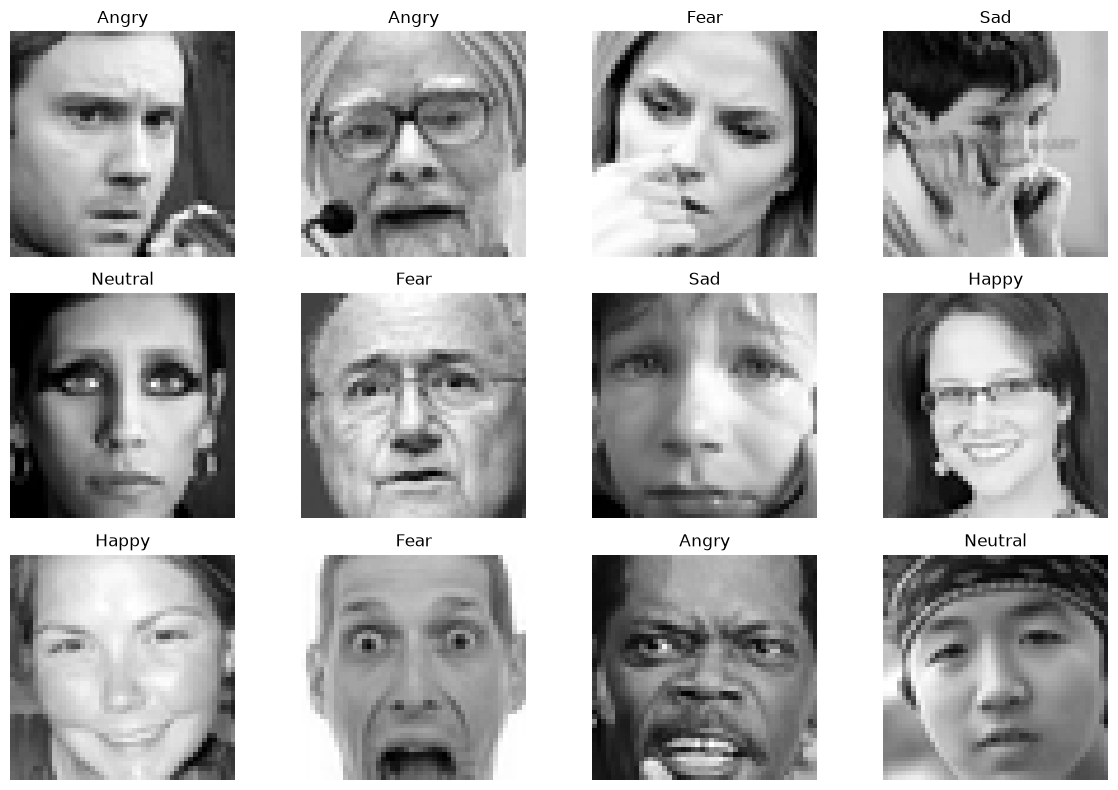

In [7]:
# step 3:
import numpy as np
import matplotlib.pyplot as plt

emotion_names = {
    0: "Angry",
    1: "Disgust",
    2: "Fear",
    3: "Happy",
    4: "Sad",
    5: "Surprise",
    6: "Neutral"
}

plt.figure(figsize=(12, 8))

for i in range(12):
    pixels = data.iloc[i]["pixels"]
    
    image = np.array(pixels.split(), dtype=np.uint8)
    image = image.reshape(48, 48)
    
    emotion = int(data.iloc[i]["emotion"])
    
    plt.subplot(3, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(emotion_names[emotion])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
# Step 4 — Convert the pixel data into images
import numpy as np

# Convert pixel strings into numerical arrays
X = np.array([
    np.array(pixels.split(), dtype=np.uint8)
    for pixels in data["pixels"]
])

# Reshape into 48x48 grayscale images
X = X.reshape(-1, 48, 48, 1)

# Get emotion labels
y = data["emotion"].values

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (28709, 48, 48, 1)
y shape: (28709,)


In [9]:
# Step 5 — Normalize the images
X = X.astype("float32") / 255.0

print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [10]:
# Step 6 — Split the dataset
from sklearn.model_selection import train_test_split

# First split: 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (22967, 48, 48, 1) (22967,)
Validation: (2871, 48, 48, 1) (2871,)
Testing: (2871, 48, 48, 1) (2871,)


In [11]:
# Step 7 — Build the CNN 🧠
import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    
    layers.Input(shape=(48, 48, 1)),
    
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    
    layers.Dense(7, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 46, 46, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 23, 23, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 21, 21, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,847 (1.36 MB)

 Trainable params: 355,847 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Step 8 — Compile the CNN
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [13]:
# tep 9 : train your CNN
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64
)

Epoch 1/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.2670 - loss: 1.7863 - val_accuracy: 0.3751 - val_loss: 1.6494
Epoch 2/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.3847 - loss: 1.5832 - val_accuracy: 0.4242 - val_loss: 1.4765
Epoch 3/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.4340 - loss: 1.4698 - val_accuracy: 0.4716 - val_loss: 1.3871
Epoch 4/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 8s 23ms/step - accuracy: 0.4643 - loss: 1.3978 - val_accuracy: 0.4995 - val_loss: 1.3381
Epoch 5/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.4918 - loss: 1.3363 - val_accuracy: 0.5033 - val_loss: 1.2800
Epoch 6/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.5080 - loss: 1.2935 - val_accuracy: 0.5239 - val_loss: 1.2363
Epoch 7/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 9s 24ms/step - accuracy: 0.5217 - loss: 1.2618 - val_accuracy: 0.5270 - val_loss: 1.2370
Epoch 8/20
359/359 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.5329 - loss: 1.2236 - val_acc

In [14]:
# step 10
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5629 - loss: 1.2289
Test Loss: 1.228930115699768
Test Accuracy: 0.5628700852394104


90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


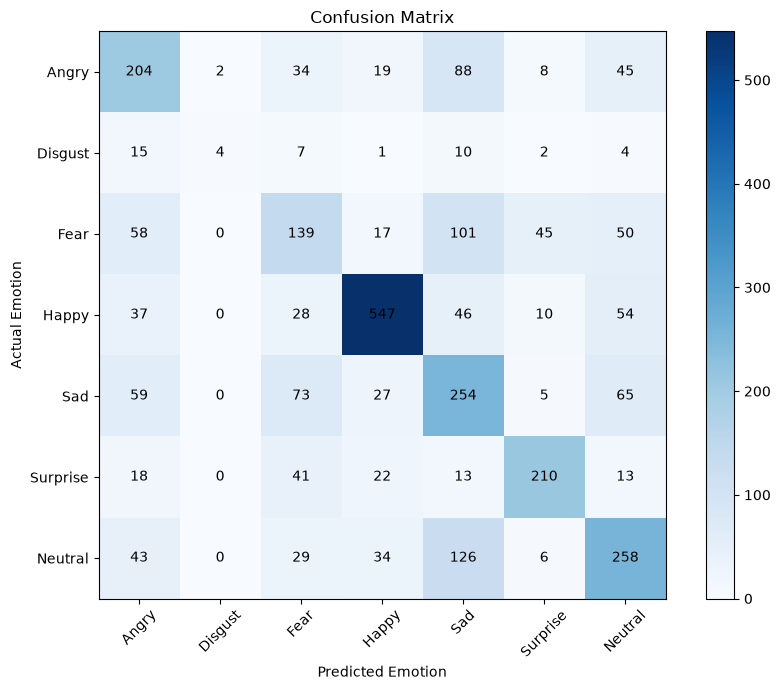

In [15]:
# step 11
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import numpy as np

# Get predictions
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

# Emotion names
emotion_names = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))
plt.imshow(cm, cmap="Blues")

plt.title("Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")

plt.xticks(range(7), emotion_names, rotation=45)
plt.yticks(range(7), emotion_names)

# Display numbers
for i in range(7):
    for j in range(7):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

In [16]:
# step 12
print(classification_report(
    y_test,
    y_pred,
    target_names=emotion_names
))

              precision    recall  f1-score   support

       Angry       0.47      0.51      0.49       400
     Disgust       0.67      0.09      0.16        43
        Fear       0.40      0.34      0.37       410
       Happy       0.82      0.76      0.79       722
         Sad       0.40      0.53      0.45       483
    Surprise       0.73      0.66      0.70       317
     Neutral       0.53      0.52      0.52       496

    accuracy                           0.56      2871
   macro avg       0.57      0.49      0.50      2871
weighted avg       0.58      0.56      0.56      2871



In [18]:
#step13
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class weights:")

for emotion, weight in class_weight_dict.items():
    print(emotion_names[emotion], ":", round(weight, 2))

Class weights:
Angry : 1.03
Disgust : 9.4
Fear : 1.0
Happy : 0.57
Sad : 0.85
Surprise : 1.29
Neutral : 0.83


In [22]:
# Step 14 — Build the improved CNN
import tensorflow as tf
from tensorflow.keras import layers, models

improved_model = models.Sequential([
    
    layers.Input(shape=(48, 48, 1)),
    
    # Block 1
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    
    # Block 2
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),
    
    # Block 3
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.30),
    
    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.50),
    
    # 7 emotions
    layers.Dense(7, activation="softmax")
])

improved_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 878,695 (3.35 MB)

 Trainable params: 877,991 (3.35 MB)

 Non-trainable params: 704 (2.75 KB)

In [24]:
# Step 15 — Compile the improved model#
improved_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Improved model compiled successfully!")

Improved model compiled successfully!


In [25]:
# Step 16 — Add automatic training controls and checkpoints

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Save the best model automatically
checkpoint = ModelCheckpoint(
    "best_emotion_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Reduce learning rate if validation loss stops improving
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

print("Callbacks and checkpoint are ready!")

Callbacks and checkpoint are ready!


In [26]:
# Step 17 — Train the improved CNN

history_improved = improved_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[
        checkpoint,
        early_stopping,
        reduce_lr
    ]
)

Epoch 1/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - accuracy: 0.2272 - loss: 2.0420
Epoch 1: val_accuracy improved from None to 0.25183, saving model to best_emotion_model.keras

Epoch 1: finished saving model to best_emotion_model.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 50s 131ms/step - accuracy: 0.2272 - loss: 2.0420 - val_accuracy: 0.2518 - val_loss: 1.8973 - learning_rate: 0.0010
Epoch 2/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.3398 - loss: 1.6998
Epoch 2: val_accuracy improved from 0.25183 to 0.38488, saving model to best_emotion_model.keras

Epoch 2: finished saving model to best_emotion_model.keras
359/359 ━━━━━━━━━━━━━━━━━━━━ 81s 130ms/step - accuracy: 0.3398 - loss: 1.6998 - val_accuracy: 0.3849 - val_loss: 1.6171 - learning_rate: 0.0010
Epoch 3/30
359/359 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.4126 - loss: 1.5284
Epoch 3: val_accuracy improved from 0.38488 to 0.40822, saving model to best_emotion_model.keras

Epoch 3: finished saving model to best_

In [27]:
# Step 18 — Load and evaluate the best saved model

from tensorflow.keras.models import load_model

best_model = load_model("best_emotion_model.keras")

test_loss, test_accuracy = best_model.evaluate(X_test, y_test)

print("Best Model Test Loss:", test_loss)
print("Best Model Test Accuracy:", test_accuracy)

90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - accuracy: 0.6336 - loss: 1.0451
Best Model Test Loss: 1.0450798273086548
Best Model Test Accuracy: 0.6335771679878235


90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step


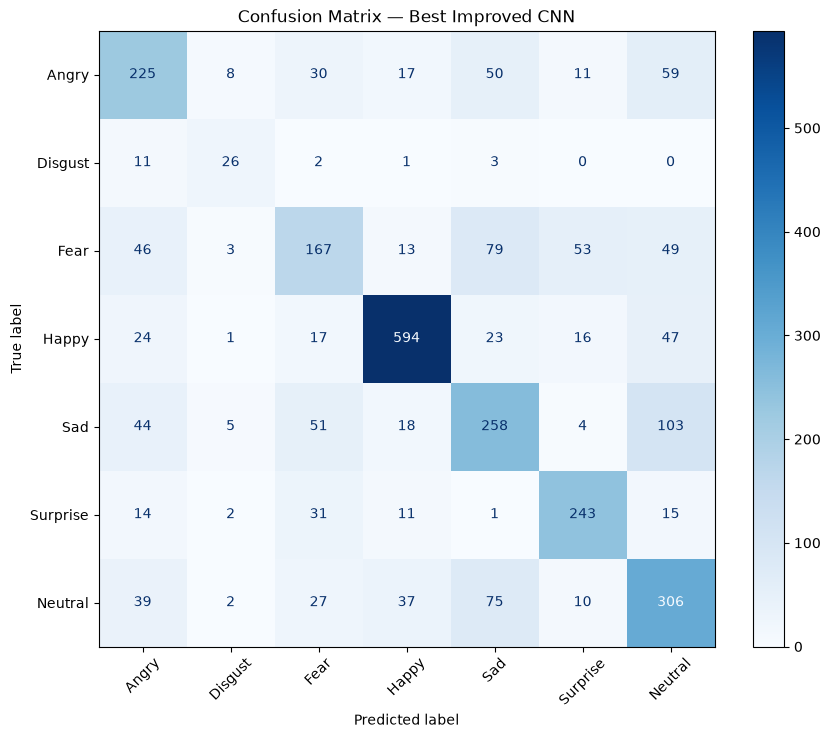

In [28]:
# Step 19 — Confusion Matrix for the Best Model

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict emotions
y_pred_prob = best_model.predict(X_test)

# Convert probabilities to emotion class numbers
y_pred = np.argmax(y_pred_prob, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Emotion names
emotion_labels = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=emotion_labels
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix — Best Improved CNN")
plt.show()

In [29]:
# Step 20 — Classification Report

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=emotion_labels
    )
)

              precision    recall  f1-score   support

       Angry       0.56      0.56      0.56       400
     Disgust       0.55      0.60      0.58        43
        Fear       0.51      0.41      0.45       410
       Happy       0.86      0.82      0.84       722
         Sad       0.53      0.53      0.53       483
    Surprise       0.72      0.77      0.74       317
     Neutral       0.53      0.62      0.57       496

    accuracy                           0.63      2871
   macro avg       0.61      0.62      0.61      2871
weighted avg       0.64      0.63      0.63      2871



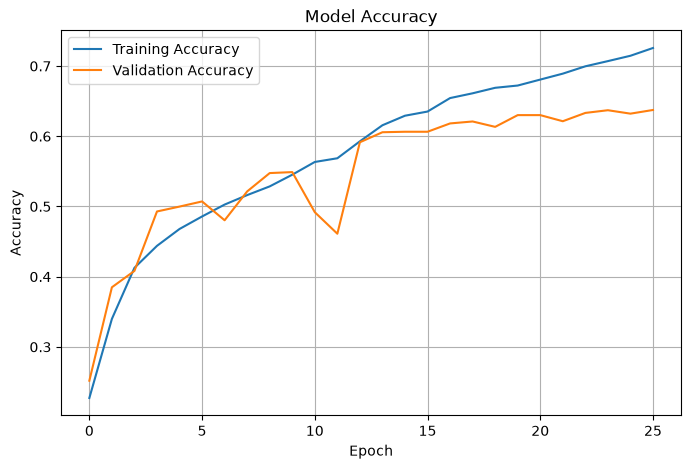

In [30]:
# Step 21 — Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history_improved.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_improved.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.show()

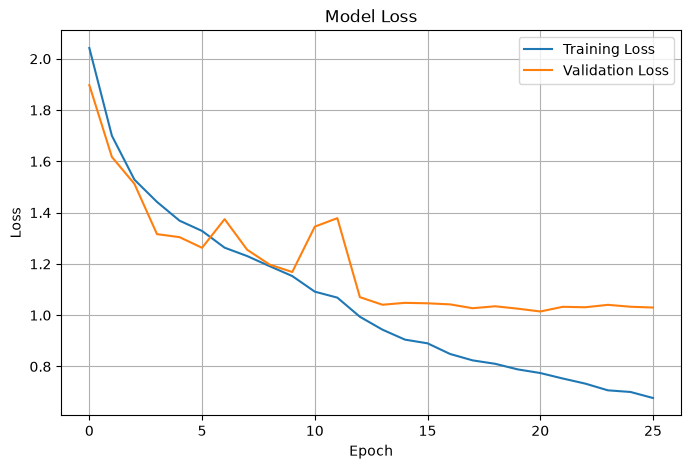

In [31]:
# Step 22 — Training and Validation Loss

plt.figure(figsize=(8, 5))

plt.plot(
    history_improved.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_improved.history["val_loss"],
    label="Validation Loss"
)

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.show()

In [32]:
# Step 23 — Save the Final Best Model

best_model.save("final_emotion_recognition_model.keras")

print("Final model saved successfully!")

Final model saved successfully!


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step


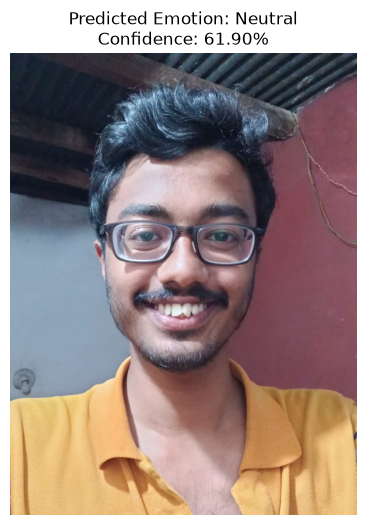

Predicted Emotion: Neutral
Confidence: 61.90%


In [37]:
# Step 24 — Load the final model and test a face image

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

# Load the final saved model
final_model = load_model("final_emotion_recognition_model.keras")

# Emotion labels
emotion_labels = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

# Load the test image
image = cv2.imread("test_face.jpeg")

# Check if image was loaded successfully
if image is None:
    print("Error: Image not found. Check the filename and location.")
else:
    # Convert BGR image to RGB for display
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convert image to grayscale
    gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Resize to the model input size
    resized_image = cv2.resize(gray_image, (48, 48))

    # Normalize pixel values
    normalized_image = resized_image / 255.0

    # Reshape for CNN
    input_image = normalized_image.reshape(1, 48, 48, 1)

    # Predict emotion
    prediction = final_model.predict(input_image)

    predicted_class = np.argmax(prediction)

    predicted_emotion = emotion_labels[predicted_class]

    confidence = prediction[0][predicted_class] * 100

    # Display image and result
    plt.figure(figsize=(6, 6))
    plt.imshow(image_rgb)

    plt.title(
        f"Predicted Emotion: {predicted_emotion}\n"
        f"Confidence: {confidence:.2f}%"
    )

    plt.axis("off")
    plt.show()

    print("Predicted Emotion:", predicted_emotion)
    print("Confidence:", f"{confidence:.2f}%")

Number of faces detected: 1
Predicted Emotion: Happy
Confidence: 95.43%


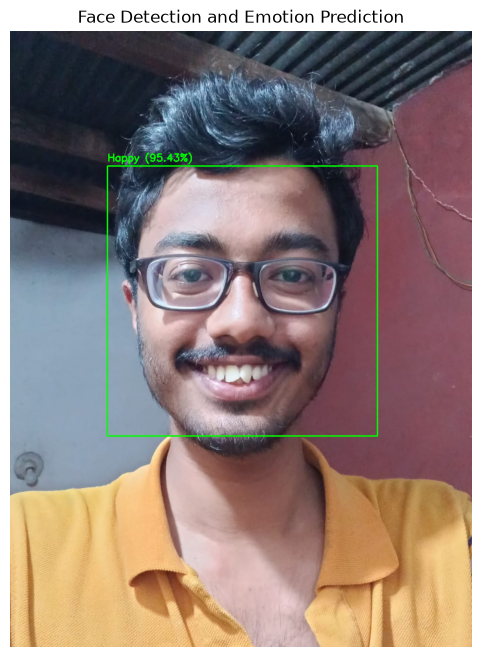

In [38]:
# Step 25 — Detect Face and Predict Emotion

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load Haar Cascade face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Load the test image
image = cv2.imread("test_face.jpeg")

# Check whether image loaded successfully
if image is None:
    print("Error: Image not found. Check the filename and location.")

else:
    # Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detect faces
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    print("Number of faces detected:", len(faces))

    # Check if a face was detected
    if len(faces) == 0:
        print("No face detected.")

    else:
        # Process each detected face
        for (x, y, w, h) in faces:

            # Crop the detected face
            face = gray[y:y+h, x:x+w]

            # Resize to model input size
            face_resized = cv2.resize(
                face,
                (48, 48)
            )

            # Normalize pixel values
            face_normalized = face_resized.astype("float32") / 255.0

            # Reshape for CNN
            face_input = face_normalized.reshape(
                1, 48, 48, 1
            )

            # Predict emotion
            prediction = final_model.predict(
                face_input,
                verbose=0
            )

            # Get predicted class
            predicted_class = np.argmax(prediction)

            # Get emotion name
            predicted_emotion = emotion_labels[
                predicted_class
            ]

            # Calculate confidence
            confidence = (
                prediction[0][predicted_class] * 100
            )

            # Draw rectangle around face
            cv2.rectangle(
                image,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            # Text to display
            text = (
                f"{predicted_emotion} "
                f"({confidence:.2f}%)"
            )

            # Add emotion text above the face
            cv2.putText(
                image,
                text,
                (x, max(y - 10, 30)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2
            )

            # Print prediction
            print("Predicted Emotion:", predicted_emotion)
            print("Confidence:", f"{confidence:.2f}%")

        # Convert image from BGR to RGB
        result_image = cv2.cvtColor(
            image,
            cv2.COLOR_BGR2RGB
        )

        # Display the final result
        plt.figure(figsize=(8, 8))
        plt.imshow(result_image)
        plt.title("Face Detection and Emotion Prediction")
        plt.axis("off")
        plt.show()

In [39]:
# Step 27 — Real-Time Webcam Emotion Detection

import cv2
import numpy as np

# Load face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Emotion labels
emotion_labels = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

# Open the default webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Error: Could not open the camera.")

else:
    print("Camera started successfully.")
    print("Press 'q' to quit.")

    while True:

        # Capture frame from webcam
        ret, frame = cap.read()

        if not ret:
            print("Error: Could not read camera frame.")
            break

        # Convert frame to grayscale
        gray = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2GRAY
        )

        # Detect faces
        faces = face_cascade.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(30, 30)
        )

        # Process each detected face
        for (x, y, w, h) in faces:

            # Crop the face
            face = gray[y:y+h, x:x+w]

            # Resize to CNN input size
            face_resized = cv2.resize(
                face,
                (48, 48)
            )

            # Normalize pixel values
            face_normalized = (
                face_resized.astype("float32") / 255.0
            )

            # Reshape for CNN
            face_input = face_normalized.reshape(
                1,
                48,
                48,
                1
            )

            # Predict emotion
            prediction = final_model.predict(
                face_input,
                verbose=0
            )

            # Get predicted emotion
            predicted_class = np.argmax(prediction)
            predicted_emotion = emotion_labels[predicted_class]

            # Get confidence
            confidence = (
                prediction[0][predicted_class] * 100
            )

            # Draw rectangle around the face
            cv2.rectangle(
                frame,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            # Display emotion and confidence
            text = (
                f"{predicted_emotion} "
                f"{confidence:.1f}%"
            )

            cv2.putText(
                frame,
                text,
                (x, max(y - 10, 30)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2
            )

        # Show live camera
        cv2.imshow(
            "Real-Time Emotion Recognition",
            frame
        )

        # Press q to close
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

# Release camera
cap.release()
cv2.destroyAllWindows()

print("Camera closed successfully.")

Camera started successfully.
Press 'q' to quit.
Camera closed successfully.


In [42]:
# Step 28 — Stable Real-Time Emotion Recognition

import cv2
import numpy as np
from collections import deque

# Load face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Emotion labels
emotion_labels = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

# Store predictions from recent frames
prediction_history = deque(maxlen=10)

# Open webcam
cap = cv2.VideoCapture(0)

if not cap.isOpened():
    print("Error: Could not open the camera.")

else:
    print("Stable emotion detection started.")
    print("Click the camera window and press 'q' to quit.")

    while True:

        # Read frame
        ret, frame = cap.read()

        if not ret:
            print("Error: Could not read camera frame.")
            break

        # Convert frame to grayscale
        gray = cv2.cvtColor(
            frame,
            cv2.COLOR_BGR2GRAY
        )

        # Detect faces
        faces = face_cascade.detectMultiScale(
            gray,
            scaleFactor=1.1,
            minNeighbors=5,
            minSize=(60, 60)
        )

        if len(faces) > 0:

            # Select the largest detected face
            largest_face = max(
                faces,
                key=lambda face: face[2] * face[3]
            )

            x, y, w, h = largest_face

            # Crop face
            face = gray[y:y+h, x:x+w]

            # Resize to model input size
            face_resized = cv2.resize(
                face,
                (48, 48)
            )

            # Normalize
            face_normalized = (
                face_resized.astype("float32") / 255.0
            )

            # Reshape for CNN
            face_input = face_normalized.reshape(
                1, 48, 48, 1
            )

            # Predict emotion
            prediction = final_model.predict(
                face_input,
                verbose=0
            )

            # Store prediction probabilities
            prediction_history.append(prediction[0])

            # Average recent predictions
            average_prediction = np.mean(
                prediction_history,
                axis=0
            )

            # Get stable emotion
            predicted_class = np.argmax(
                average_prediction
            )

            predicted_emotion = emotion_labels[
                predicted_class
            ]

            confidence = (
                average_prediction[predicted_class]
                * 100
            )

            # Draw rectangle
            cv2.rectangle(
                frame,
                (x, y),
                (x + w, y + h),
                (0, 255, 0),
                2
            )

            # Display prediction
            text = (
                f"{predicted_emotion} "
                f"{confidence:.1f}%"
            )

            cv2.putText(
                frame,
                text,
                (x, max(y - 10, 30)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )

        else:
            # Clear old predictions when no face is detected
            prediction_history.clear()

            cv2.putText(
                frame,
                "No face detected",
                (20, 40),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 0, 255),
                2
            )

        # Display camera window
        cv2.imshow(
            "Stable Real-Time Emotion Recognition",
            frame
        )

        # Press q to exit
        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

# Release camera
cap.release()
cv2.destroyAllWindows()

print("Camera closed successfully.")

Stable emotion detection started.
Click the camera window and press 'q' to quit.
Camera closed successfully.
